# B4 — Penapisan Citra

Notebook praktikum. Tambahkan langkah dan kode sesuai instruksi modul.

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import sys
import os

sys.path.append("../src")

from utils_cv import baca, tampil, kontras_bercak, statistik

print("OpenCV:", cv2.__version__)
print("Persiapan B4 berhasil.")

OpenCV: 5.0.0
Persiapan B4 berhasil.


In [8]:
# Kode 4.1 Verifikasi konvolusi manual
import time

def konvolusi(img, k):            # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):     # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"),
                      cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
              }.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.127 s, filter2D=0.01601 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=2.222 s, filter2D=0.00040 s


In [9]:
# Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB
import pandas as pd
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):                  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):        # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih,
20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
                  kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB",
                                     "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  4.08
1   gauss_10  rerata_3    36.94      0.14  6.24
2   gauss_10  rerata_5    37.88      0.16  6.10
3   gauss_10   gauss_5    37.80      0.30  6.35
4   gauss_10  median_3    35.55      0.09  6.32
5   gauss_10  median_5    38.73      0.74  7.01
6   gauss_10  median_9    39.76     13.47  7.38
7   gauss_20     tanpa    22.11      0.00  2.34
8   gauss_20  rerata_3    31.45      0.14  5.05
9   gauss_20  rerata_5    34.61      0.16  5.60
10  gauss_20   gauss_5    32.60      0.29  5.34
11  gauss_20  median_3    29.75      0.10  4.64
12  gauss_20  median_5    33.58      0.73  5.75
13  gauss_20  median_9    36.15     14.62  6.04
14  gauss_40     tanpa    16.55      0.00  1.21
15  gauss_40  rerata_3    25.98      0.14  3.30
16  gauss_40  rerata_5    29.88      0.16  4.46
17  gauss_40   gauss_5    27.18      0.30  3.67
18  gauss_40  median_3    23.83      0.10  2.74
19  gauss_40  median_5    27.86      0.7

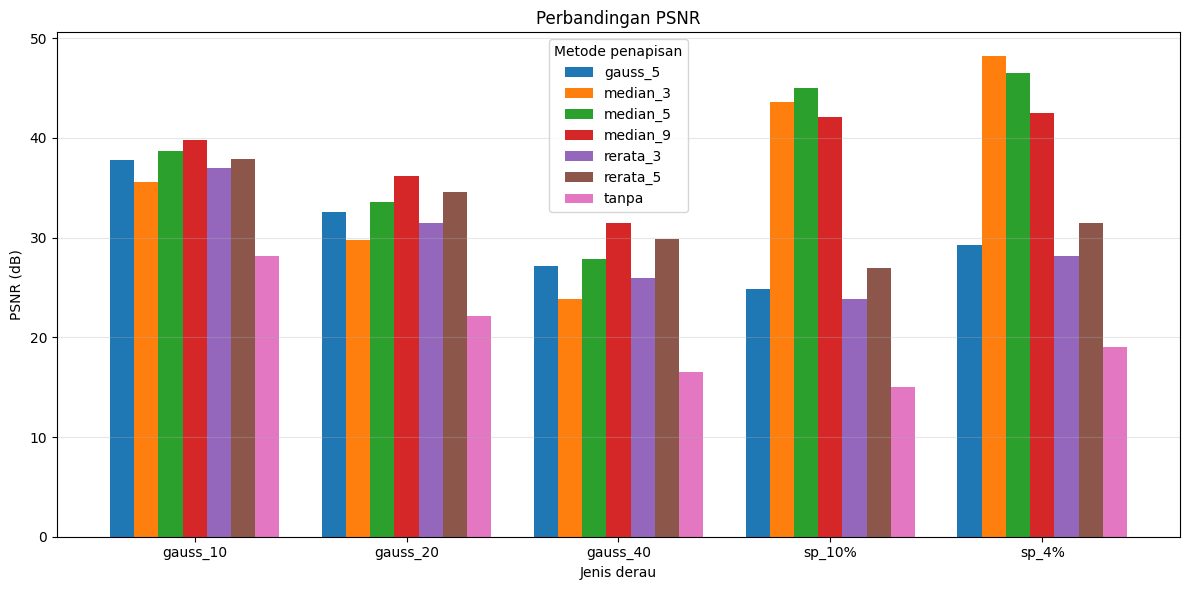

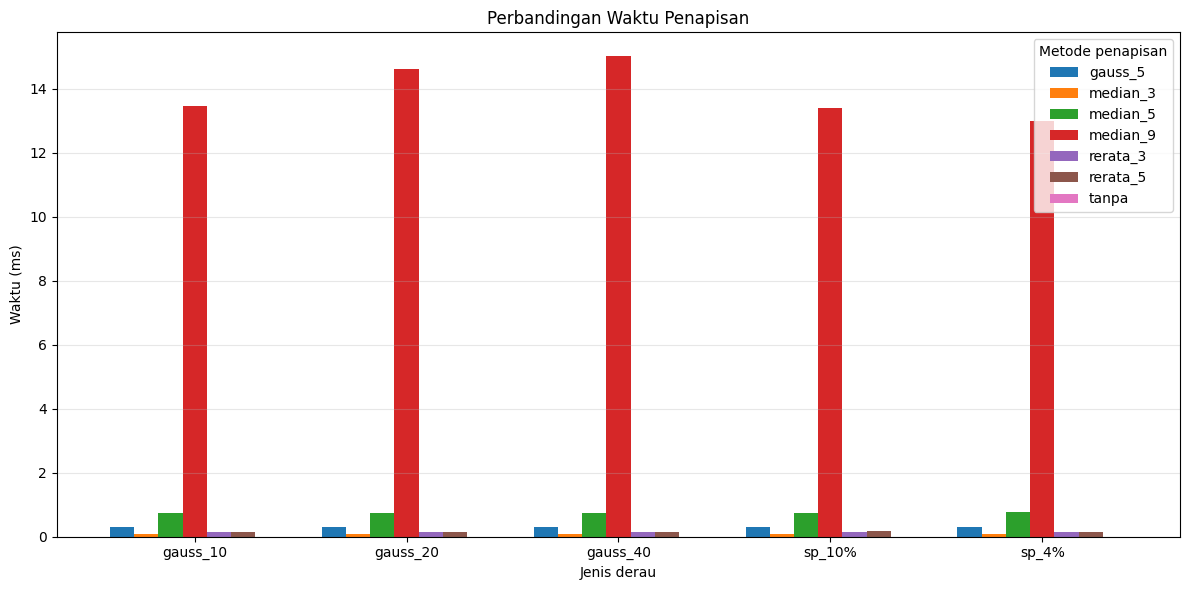

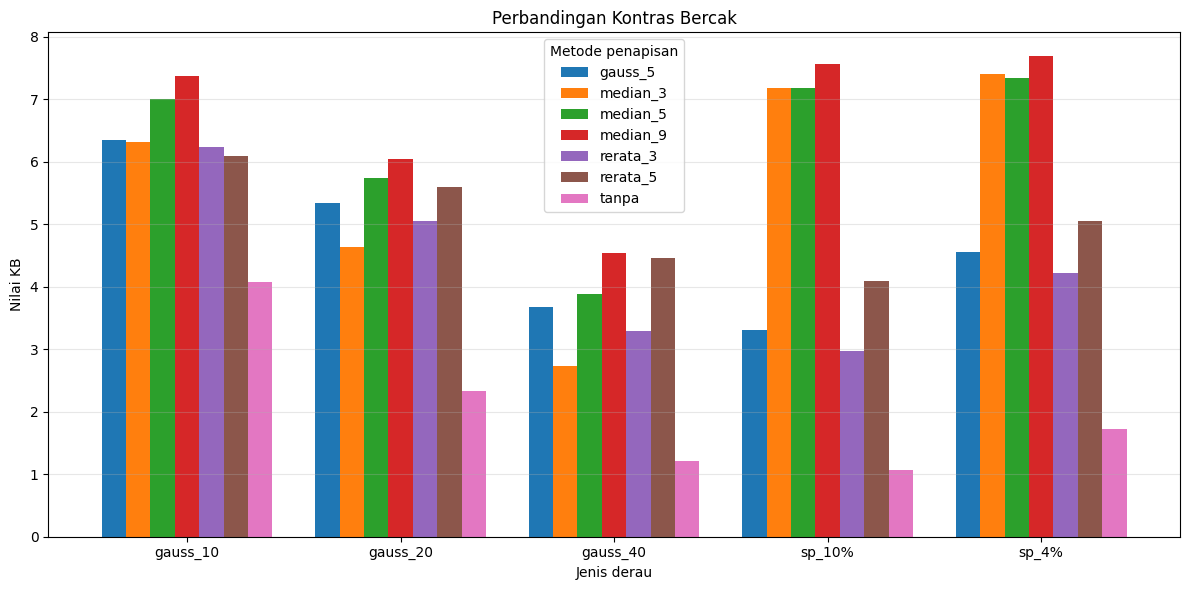

In [10]:
# Grafik PSNR, waktu, dan KB untuk seluruh jenis derau

metrik = [
    ("PSNR_dB", "Perbandingan PSNR", "PSNR (dB)",
     "b4_grafik_psnr.png"),
    ("waktu_ms", "Perbandingan Waktu Penapisan", "Waktu (ms)",
     "b4_grafik_waktu.png"),
    ("KB", "Perbandingan Kontras Bercak", "Nilai KB",
     "b4_grafik_kb.png")
]

for kolom, judul, label_y, nama_file in metrik:
    grafik = tabel.pivot(
        index="derau",
        columns="penapis",
        values=kolom
    )

    ax = grafik.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8
    )

    ax.set_title(judul)
    ax.set_xlabel("Jenis derau")
    ax.set_ylabel(label_y)
    ax.legend(title="Metode penapisan")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f"../hasil/{nama_file}", dpi=300)
    plt.show()

In [12]:
# Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:          # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
print(hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2))

           dI    KB
kernel             
1       29.38  4.68
3       29.92  4.84
5       28.98  4.75
9       23.36  4.41
15       9.03  2.45


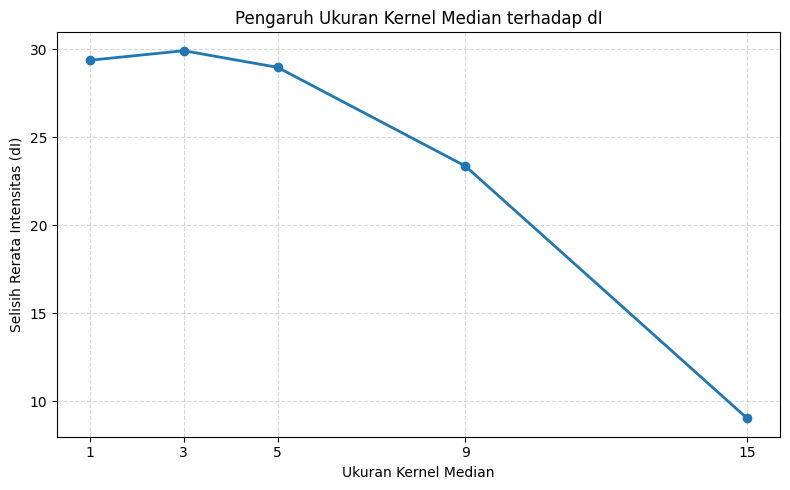

In [13]:
# Grafik pengaruh ukuran kernel median terhadap dI

rata_median = hasil_median.groupby("kernel")[["dI", "KB"]].mean()

plt.figure(figsize=(8, 5))

plt.plot(
    rata_median.index,
    rata_median["dI"],
    marker="o",
    linewidth=2
)

plt.title("Pengaruh Ukuran Kernel Median terhadap dI")
plt.xlabel("Ukuran Kernel Median")
plt.ylabel("Selisih Rerata Intensitas (dI)")
plt.xticks([1, 3, 5, 9, 15])
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    "../hasil/b4_grafik_dI_kernel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Kode 4.4 Pengaruh urutan penajaman
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0                         # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))           # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))           # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.42 sigma_latar=7.8 | redam->tajam PSNR=30.21 sigma_latar=8.1
Median: tajam->redam PSNR=30.20 sigma_latar=8.0 | redam->tajam PSNR=31.17 sigma_latar=7.1


In [15]:
# Langkah 4.6 Pengujian PSNR pada 12 citra kondisi normal
# Penapis pilihan: Median Filter 3x3

daftar_citra = [
    "teh_001.png",
    "teh_006.png",
    "teh_011.png",
    "teh_016.png",
    "teh_021.png",
    "teh_026.png",
    "teh_031.png",
    "teh_036.png",
    "teh_041.png",
    "teh_046.png",
    "teh_051.png",
    "teh_056.png"
]

baris = []

for nama in daftar_citra:

    # Membaca citra yang memiliki derau sensor bawaan
    img = baca(f"../data/sintetis/citra/{nama}")

    # Membaca pasangan citra bersih sebagai referensi
    bersih_ref = baca(f"../data/sintetis/bersih/{nama}")

    # Memastikan citra berhasil dibaca
    if img is None or bersih_ref is None:
        raise ValueError(f"Citra tidak ditemukan: {nama}")

    # Memastikan ukuran citra sama
    if img.shape != bersih_ref.shape:
        raise ValueError(f"Ukuran citra tidak sama: {nama}")

    # Menghitung PSNR sebelum penapisan
    psnr_sebelum = cv2.PSNR(bersih_ref, img)

    # Menerapkan Median Filter 3x3
    hasil = cv2.medianBlur(img, 3)

    # Menghitung PSNR sesudah penapisan
    psnr_sesudah = cv2.PSNR(bersih_ref, hasil)

    baris.append([
        nama.replace(".png", ""),
        psnr_sebelum,
        psnr_sesudah
    ])

# Membuat DataFrame hasil pengujian
tabel_psnr = pd.DataFrame(
    baris,
    columns=[
        "Citra",
        "PSNR sebelum (dB)",
        "PSNR sesudah (dB)"
    ]
)

# Menghitung rata-rata dari 12 citra
rata_rata = pd.DataFrame([{
    "Citra": "Rerata",
    "PSNR sebelum (dB)": tabel_psnr["PSNR sebelum (dB)"].mean(),
    "PSNR sesudah (dB)": tabel_psnr["PSNR sesudah (dB)"].mean()
}])

tabel_psnr = pd.concat(
    [tabel_psnr, rata_rata],
    ignore_index=True
)

# Menampilkan hasil
print("Penapis pilihan: Median Filter 3x3")
display(tabel_psnr.round(2))

# Menyimpan hasil ke CSV
tabel_psnr.to_csv(
    "../hasil/b4_psnr_12_citra_normal.csv",
    index=False
)

Penapis pilihan: Median Filter 3x3


,Citra,PSNR sebelum (dB),PSNR sesudah (dB)
0,teh_001,27.53,34.97
1,teh_006,25.98,33.48
2,teh_011,32.00,39.09
3,teh_016,28.36,35.76
4,teh_021,29.96,37.23
5,teh_026,25.52,33.05
6,teh_031,26.84,34.28
7,teh_036,29.05,36.39
8,teh_041,31.51,38.59
9,teh_046,26.64,34.08
